### Test model performance on different train-test splits by iteratively adjusting data distributions, evaluating shifts in accuracy, and ensuring stability across multiple randomized and stratified splits.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [22]:
df = pd.read_csv("heart_disease.csv")

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

display(df.head())
print(df.columns.tolist())

Dataset loaded successfully
Dataset shape: (25, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [23]:
print(df.columns.tolist())

target_column = "target"

if target_column not in df.columns:
    raise ValueError(
        f"'{target_column}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df.dropna(subset=[target_column]).copy()

X = df.drop(columns=[target_column])
y = df[target_column]

X = pd.get_dummies(X, drop_first=True, dtype=int)

if not pd.api.types.is_numeric_dtype(y):
    y = pd.factorize(y)[0]

X = X.reset_index(drop=True)
y = pd.Series(np.asarray(y).ravel()).reset_index(drop=True)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
X shape: (25, 13)
y shape: (25,)

Target distribution:
1    16
0     9
Name: count, dtype: int64


In [24]:
models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(probability=True, random_state=42)
    ),

    "Decision Tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        )
    )
}

print("Models defined successfully")

Models defined successfully


In [25]:
results = []

test_sizes = [0.30, 0.25, 0.20]
random_seeds = [11, 21, 42, 55, 75]

for test_size in test_sizes:
    for seed in random_seeds:

        for method in ["Random", "Stratified"]:

            stratify = y if method == "Stratified" else None

            if method == "Stratified" and y.value_counts().min() < 2:
                continue

            try:
                X_train, X_test, y_train, y_test = train_test_split(
                    X,
                    y,
                    test_size=test_size,
                    random_state=seed,
                    stratify=stratify
                )
            except ValueError as e:
                print("Split skipped:", e)
                continue

            for name, model in models.items():

                fitted_model = clone(model)
                fitted_model.fit(X_train, y_train)

                y_pred = fitted_model.predict(X_test)

                auc = np.nan

                if y.nunique() == 2:
                    try:
                        y_score = fitted_model.predict_proba(X_test)[:, 1]
                        auc = roc_auc_score(y_test, y_score)
                    except (ValueError, IndexError):
                        pass

                results.append({
                    "Model": name,
                    "Train Size": round(1 - test_size, 2),
                    "Test Size": test_size,
                    "Split Method": method,
                    "Random Seed": seed,
                    "Accuracy": accuracy_score(y_test, y_pred),
                    "Precision": precision_score(
                        y_test, y_pred,
                        average="weighted",
                        zero_division=0
                    ),
                    "Recall": recall_score(
                        y_test, y_pred,
                        average="weighted",
                        zero_division=0
                    ),
                    "F1 Score": f1_score(
                        y_test, y_pred,
                        average="weighted",
                        zero_division=0
                    ),
                    "ROC-AUC": auc
                })

results_df = pd.DataFrame(results)

display(results_df.head(10))
print("Total experiments:", len(results_df))

C:\Users\Bhagyashri\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Bhagyashri\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Bhagyashri\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Bhagyashri\AppData\Local\Programs\Python\Python313\Lib\site-p

,Model,Train Size,Test Size,Split Method,Random Seed,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7,0.3,Random,11,0.750,0.750000,0.750,0.750000,0.714286
1,KNN,0.7,0.3,Random,11,0.625,0.729167,0.625,0.673077,0.571429
2,SVM,0.7,0.3,Random,11,0.750,0.916667,0.750,0.791667,1.000000
3,Decision Tree,0.7,0.3,Random,11,0.750,0.750000,0.750,0.750000,0.428571
4,Random Forest,0.7,0.3,Random,11,0.875,0.937500,0.875,0.891026,1.000000
5,Logistic Regression,0.7,0.3,Stratified,11,0.750,0.850000,0.750,0.750000,0.800000
6,KNN,0.7,0.3,Stratified,11,0.625,0.604167,0.625,0.604545,0.766667
7,SVM,0.7,0.3,Stratified,11,0.625,0.604167,0.625,0.604545,0.666667
8,Decision Tree,0.7,0.3,Stratified,11,0.500,0.566667,0.500,0.500000,0.533333
9,Random Forest,0.7,0.3,Stratified,11,0.625,0.656250,0.625,0.630952,0.733333


Total experiments: 150


In [26]:
summary = results_df.groupby("Model").agg(
    Mean_Accuracy=("Accuracy", "mean"),
    Std_Accuracy=("Accuracy", "std"),
    Mean_Precision=("Precision", "mean"),
    Mean_Recall=("Recall", "mean"),
    Mean_F1=("F1 Score", "mean"),
    Mean_ROC_AUC=("ROC-AUC", "mean")
).round(4)

display(summary.sort_values("Mean_Accuracy", ascending=False))

,Mean_Accuracy,Std_Accuracy,Mean_Precision,Mean_Recall,Mean_F1,Mean_ROC_AUC
Model,,,,,,
SVM,0.7506,0.1418,0.7827,0.7506,0.7376,0.8713
Logistic Regression,0.7443,0.1416,0.7730,0.7443,0.7391,0.8229
KNN,0.7295,0.1480,0.7279,0.7295,0.7001,0.8263
Random Forest,0.7125,0.1386,0.7401,0.7125,0.7008,0.8431
Decision Tree,0.6386,0.2082,0.6501,0.6386,0.6332,0.5573


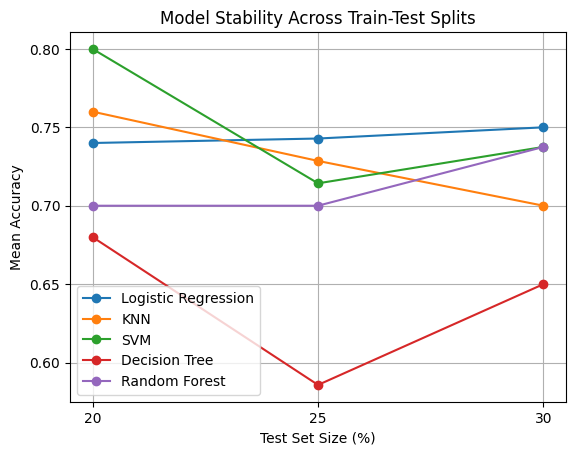

In [27]:
plot_data = results_df.groupby(
    ["Model", "Test Size"]
)["Accuracy"].mean().reset_index()

for name in models:
    data = plot_data[plot_data["Model"] == name]

    plt.plot(
        data["Test Size"] * 100,
        data["Accuracy"],
        marker="o",
        label=name
    )

plt.xlabel("Test Set Size (%)")
plt.ylabel("Mean Accuracy")
plt.title("Model Stability Across Train-Test Splits")
plt.xticks([20, 25, 30])
plt.legend()
plt.grid(True)
plt.show()

In [28]:
stability = results_df.groupby("Model")["Accuracy"].agg(
    ["mean", "std", "min", "max"]
).round(4)

stability["Accuracy_Range"] = (
    stability["max"] - stability["min"]
)

display(stability.sort_values("std", ascending=True))

,mean,std,min,max,Accuracy_Range
Model,,,,,
Random Forest,0.7125,0.1386,0.4000,1.0,0.6000
Logistic Regression,0.7443,0.1416,0.4000,1.0,0.6000
SVM,0.7506,0.1418,0.5714,1.0,0.4286
KNN,0.7295,0.1480,0.4000,1.0,0.6000
Decision Tree,0.6386,0.2082,0.2000,1.0,0.8000


### Perform adversarial testing by slightly modifying input features using perturbation techniques, manually designing worst-case adversarial samples, and quantifying their impact on model robustness.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

model.fit(X_train, y_train)

y_original = model.predict(X_test)

print("Baseline Accuracy:",
      round(accuracy_score(y_test, y_original), 4))

print("Baseline F1 Score:",
      round(f1_score(y_test, y_original,
                     average="weighted", zero_division=0), 4))

Baseline Accuracy: 0.8
Baseline F1 Score: 0.781


In [30]:
continuous_features = [
    col for col in X_train.columns
    if pd.api.types.is_numeric_dtype(X_train[col])
    and X_train[col].nunique() > 10
]

if not continuous_features:
    raise ValueError(
        "No continuous numerical features found. "
        "Inspect X_train and choose appropriate features manually."
    )

print("Features selected for perturbation:")
print(continuous_features)

feature_scales = {}

for col in continuous_features:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    feature_scales[col] = q3 - q1

display(pd.DataFrame({
    "Feature": continuous_features,
    "Training IQR": [
        feature_scales[c] for c in continuous_features
    ]
}))

Features selected for perturbation:
['age', 'chol', 'thalach', 'oldpeak']


,Feature,Training IQR
0,age,9.25
1,chol,56.50
2,thalach,22.00
3,oldpeak,1.80


In [31]:
X_perturbed = X_test.copy()

for col in continuous_features:
    shift = 0.05 * feature_scales[col]

    lower = X_train[col].quantile(0.01)
    upper = X_train[col].quantile(0.99)

    direction = np.where(
        np.arange(len(X_test)) % 2 == 0, 1, -1
    )

    X_perturbed[col] = np.clip(
        X_test[col].to_numpy() + direction * shift,
        lower,
        upper
    )

y_perturbed = model.predict(X_perturbed)

print("Original predictions:")
print(np.asarray(y_original)[:10])

print("\nPerturbed predictions:")
print(np.asarray(y_perturbed)[:10])

Original predictions:
[1 1 1 1 0]

Perturbed predictions:
[1 1 1 1 0]


In [32]:
def evaluate_predictions(y_true, y_pred, name):
    return {
        "Test Type": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

baseline_metrics = evaluate_predictions(
    y_test, y_original, "Original"
)

perturbed_metrics = evaluate_predictions(
    y_test, y_perturbed, "Small Perturbation"
)

performance_comparison = pd.DataFrame([
    baseline_metrics,
    perturbed_metrics
])

display(performance_comparison.round(4))

flip_rate = np.mean(
    np.asarray(y_original) != np.asarray(y_perturbed)
)

print(f"Prediction flip rate: {flip_rate:.2%}")
print(
    f"Accuracy change: "
    f"{accuracy_score(y_test, y_perturbed) - accuracy_score(y_test, y_original):.4f}"
)

,Test Type,Accuracy,Precision,Recall,F1 Score
0,Original,0.8,0.85,0.8,0.781
1,Small Perturbation,0.8,0.85,0.8,0.781


Prediction flip rate: 0.00%
Accuracy change: 0.0000


In [33]:
X_worst = X_test.copy()

original_predictions = model.predict(X_test)
original_probabilities = model.predict_proba(X_test)

classes = model[-1].classes_

original_class_indices = np.array([
    np.where(classes == pred)[0][0]
    for pred in original_predictions
])

original_confidence = original_probabilities[
    np.arange(len(X_test)),
    original_class_indices
]

worst_confidence = original_confidence.copy()

for col in continuous_features:
    shift = 0.25 * feature_scales[col]

    lower = X_train[col].quantile(0.01)
    upper = X_train[col].quantile(0.99)

    for direction in [-1, 1]:
        candidate = X_test.copy()

        candidate[col] = np.clip(
            X_test[col] + direction * shift,
            lower,
            upper
        )

        probabilities = model.predict_proba(candidate)

        candidate_confidence = probabilities[
            np.arange(len(X_test)),
            original_class_indices
        ]

        update_mask = candidate_confidence < worst_confidence

        X_worst.loc[update_mask, col] = candidate.loc[
            update_mask, col
        ]

        worst_confidence[update_mask] = (
            candidate_confidence[update_mask]
        )

y_worst = model.predict(X_worst)

print("Worst-case accuracy:",
      round(accuracy_score(y_test, y_worst), 4))

print("Worst-case prediction flip rate:",
      f"{np.mean(y_worst != original_predictions):.2%}")

print("Average original confidence:",
      round(original_confidence.mean(), 4))

print("Average worst-case confidence:",
      round(worst_confidence.mean(), 4))

Worst-case accuracy: 0.6
Worst-case prediction flip rate: 20.00%
Average original confidence: 0.7978
Average worst-case confidence: 0.7793


C:\Users\Bhagyashri\AppData\Local\Temp\ipykernel_21396\2669680364.py:44: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[59.6875]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_worst.loc[update_mask, col] = candidate.loc[


,Test Type,Accuracy,Precision,Recall,F1 Score
0,Original,0.8,0.85,0.8,0.781
1,Small Perturbation,0.8,0.85,0.8,0.781
2,Worst-Case Perturbation,0.6,0.36,0.6,0.450


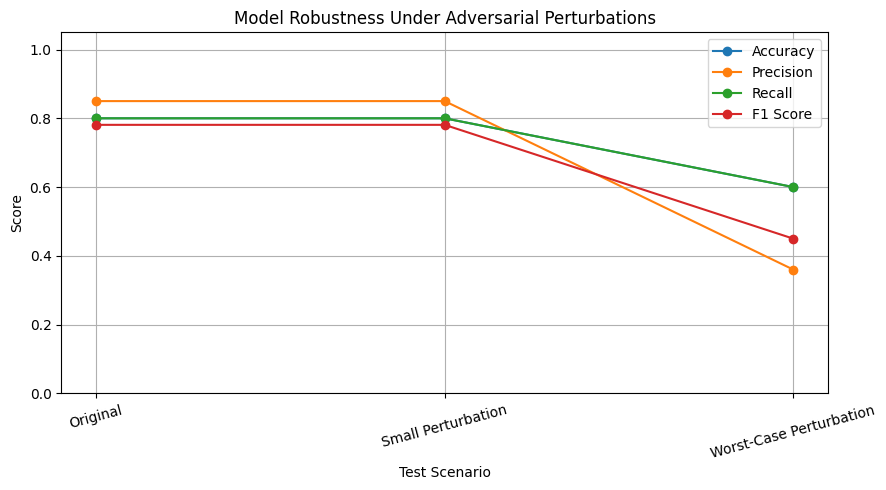

In [34]:
worst_metrics = evaluate_predictions(
    y_test, y_worst, "Worst-Case Perturbation"
)

final_comparison = pd.DataFrame([
    baseline_metrics,
    perturbed_metrics,
    worst_metrics
])

display(final_comparison.round(4))

plt.figure(figsize=(9, 5))

for metric in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    plt.plot(
        final_comparison["Test Type"],
        final_comparison[metric],
        marker="o",
        label=metric
    )

plt.title("Model Robustness Under Adversarial Perturbations")
plt.ylabel("Score")
plt.xlabel("Test Scenario")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [35]:
sample_analysis = X_test.copy()

sample_analysis["Actual"] = np.asarray(y_test)
sample_analysis["Original Prediction"] = original_predictions
sample_analysis["Perturbed Prediction"] = y_perturbed
sample_analysis["Worst-Case Prediction"] = y_worst
sample_analysis["Original Confidence"] = original_confidence
sample_analysis["Worst-Case Confidence"] = worst_confidence

sample_analysis["Prediction Changed"] = (
    sample_analysis["Original Prediction"]
    != sample_analysis["Worst-Case Prediction"]
)

sample_analysis["Confidence Drop"] = (
    original_confidence - worst_confidence
)

display(
    sample_analysis.sort_values(
        "Confidence Drop", ascending=False
    ).head(10).round(4)
)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,...,ca,thal,Actual,Original Prediction,Perturbed Prediction,Worst-Case Prediction,Original Confidence,Worst-Case Confidence,Prediction Changed,Confidence Drop
19,62,1,1,140,231,0,1,140,0,2.0,...,0,3,0,0,0,1,0.5184,0.4847,True,0.0337
6,56,0,1,140,294,0,0,153,0,1.3,...,0,2,1,1,1,1,0.7009,0.6719,False,0.0290
10,54,1,0,140,239,0,1,160,0,1.2,...,0,2,1,1,1,1,0.9046,0.8924,False,0.0123
2,41,0,1,130,204,0,0,172,0,1.4,...,0,2,1,1,1,1,0.9261,0.9163,False,0.0098
22,56,1,2,130,256,1,0,142,1,0.6,...,1,1,0,1,1,1,0.9393,0.9311,False,0.0082


In [36]:
baseline_accuracy = accuracy_score(y_test, y_original)
small_accuracy = accuracy_score(y_test, y_perturbed)
worst_accuracy = accuracy_score(y_test, y_worst)

print("===== ROBUSTNESS REPORT =====")
print(f"Baseline accuracy: {baseline_accuracy:.4f}")
print(f"Small-perturbation accuracy: {small_accuracy:.4f}")
print(f"Worst-case accuracy: {worst_accuracy:.4f}")

print(f"Small-perturbation accuracy change: "
      f"{small_accuracy - baseline_accuracy:+.4f}")

print(f"Worst-case accuracy change: "
      f"{worst_accuracy - baseline_accuracy:+.4f}")

print(f"Small-perturbation flip rate: "
      f"{np.mean(y_original != y_perturbed):.2%}")

print(f"Worst-case flip rate: "
      f"{np.mean(y_original != y_worst):.2%}")

print(f"Mean confidence reduction: "
      f"{np.mean(original_confidence - worst_confidence):.4f}")

===== ROBUSTNESS REPORT =====
Baseline accuracy: 0.8000
Small-perturbation accuracy: 0.8000
Worst-case accuracy: 0.6000
Small-perturbation accuracy change: +0.0000
Worst-case accuracy change: -0.2000
Small-perturbation flip rate: 0.00%
Worst-case flip rate: 20.00%
Mean confidence reduction: 0.0186
